In [1]:
import torchvision.models as models

# Load the pre-trained ResNet-18 model
resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Set the model to evaluation mode for inference
resnet18.eval()

print("ResNet-18 loaded successfully!")

ResNet-18 loaded successfully!


In [2]:
import os
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Grad-CAM specific libraries
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Select Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")

Using compute device: cpu


In [3]:
import pandas as pd
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch

# 1. Define and build the DataFrame (df)
DATASET_DIR = Path("/home/gabor-levai/Downloads/AI_VIS/archive (3)")
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
records = []

print(f"Scanning directory: {DATASET_DIR}")

for filepath in DATASET_DIR.rglob("*"):
    if filepath.is_file() and filepath.suffix.lower() in valid_extensions:
        parts_lower = [p.lower() for p in filepath.parts]
        
        # Categorize label based on folder structure or filename
        if any("real" in p for p in parts_lower):
            label = "Real"
        elif any("fake" in p for p in parts_lower):
            label = "Fake"
        else:
            label = "Unknown"
        
        records.append({
            "filepath": str(filepath),
            "label": label
        })

df = pd.DataFrame(records)
print(f"Scanned {len(df)} total images.")

# 2. Filter out "Unknown" items; only keep Real and Fake
df_filtered = df[df["label"].isin(["Real", "Fake"])].copy()

# 3. Split into Training (80%) and Testing (20%)
train_df, test_df = train_test_split(
    df_filtered, test_size=0.2, random_state=42, stratify=df_filtered["label"]
)

# 4. Define the PyTorch Dataset
class DeepfakeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label_map = {"Real": 1, "Fake": 0}
        
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        img_path = self.dataframe.loc[idx, "filepath"]
        label_str = self.dataframe.loc[idx, "label"]
        
        image = Image.open(img_path).convert('RGB')
        label = self.label_map[label_str]
        
        if self.transform:
            image = self.transform(image)
            
        return image, torch.tensor(label, dtype=torch.float32), img_path

# 5. Define Transforms and DataLoaders
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = DeepfakeDataset(train_df, transform=train_transform)
test_dataset = DeepfakeDataset(test_df, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Training samples: {len(train_dataset)} | Testing samples: {len(test_dataset)}")

Scanning directory: /home/gabor-levai/Downloads/AI_VIS/archive (3)
Scanned 2041 total images.
Training samples: 1632 | Testing samples: 409


In [4]:
# Load pre-trained ResNet-18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Modify the final fully connected layer for Binary Classification
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 1) # 1 output node with Sigmoid behavior later
model = model.to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

print("ResNet-18 architecture loaded and modified for binary classification.")

ResNet-18 architecture loaded and modified for binary classification.


In [5]:
num_epochs = 3 # Increase for better accuracy based on dataset size

print("Starting training...")
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels, _ in train_loader:
        images, labels = images.to(device), labels.to(device).unsqueeze(1)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        
        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch {epoch+1}/{num_epochs} - Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}")

Starting training...
Epoch 1/3 - Loss: 0.6510, Accuracy: 0.6232
Epoch 2/3 - Loss: 0.3951, Accuracy: 0.8241
Epoch 3/3 - Loss: 0.2144, Accuracy: 0.9252


In [6]:
model.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels, paths in test_loader:
        images, labels = images.to(device), labels.to(device).unsqueeze(1)
        outputs = model(images)
        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).float()
        
        all_probs.extend(probs.cpu().numpy().flatten())
        all_preds.extend(preds.cpu().numpy().flatten())
        all_labels.extend(labels.cpu().numpy().flatten())

# General metrics 
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=["Fake (0)", "Real (1)"]))


Classification Report:
              precision    recall  f1-score   support

    Fake (0)       0.73      0.55      0.63       192
    Real (1)       0.67      0.82      0.74       217

    accuracy                           0.69       409
   macro avg       0.70      0.69      0.68       409
weighted avg       0.70      0.69      0.69       409



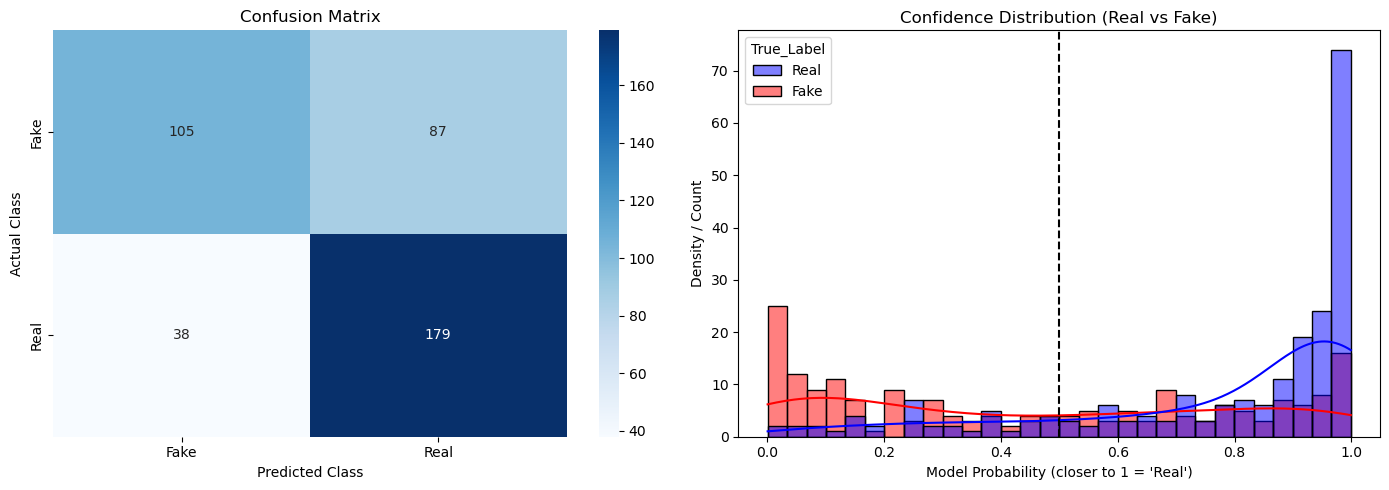


--- Statistical Reasoning ---
1. Confusion Matrix: Allows us to check for model bias. A high count of False Positives (predicting Real when actually Fake) indicates the model struggles to catch subtle AI artifacts.
2. Confidence Distribution (Histogram): The ideal model shows a bimodal split: Blue peaks near 1.0 (highly confident it is Real) and Red peaks near 0.0 (highly confident it is Fake). Data overlapping in the middle (near 0.5) represents the "hard cases" where the network is genuinely confused.



In [7]:
# Structure results for Seaborn plotting
results_df = pd.DataFrame({
    'True_Label': ['Real' if x == 1 else 'Fake' for x in all_labels],
    'Predicted_Label': ['Real' if x == 1 else 'Fake' for x in all_preds],
    'Confidence_Score': all_probs
})

plt.figure(figsize=(14, 5))

# Graph 1: Confusion Matrix
plt.subplot(1, 2, 1)
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

# Graph 2: Prediction Probability Histogram
plt.subplot(1, 2, 2)
sns.histplot(data=results_df, x='Confidence_Score', hue='True_Label', 
             bins=30, kde=True, palette={'Fake': 'red', 'Real': 'blue'})
plt.title("Confidence Distribution (Real vs Fake)")
plt.xlabel("Model Probability (closer to 1 = 'Real')")
plt.ylabel("Density / Count")
plt.axvline(x=0.5, color='black', linestyle='--')

plt.tight_layout()
plt.show()

print("""
--- Statistical Reasoning ---
1. Confusion Matrix: Allows us to check for model bias. A high count of False Positives (predicting Real when actually Fake) indicates the model struggles to catch subtle AI artifacts.
2. Confidence Distribution (Histogram): The ideal model shows a bimodal split: Blue peaks near 1.0 (highly confident it is Real) and Red peaks near 0.0 (highly confident it is Fake). Data overlapping in the middle (near 0.5) represents the "hard cases" where the network is genuinely confused.
""")

Evaluating a FAKE image:


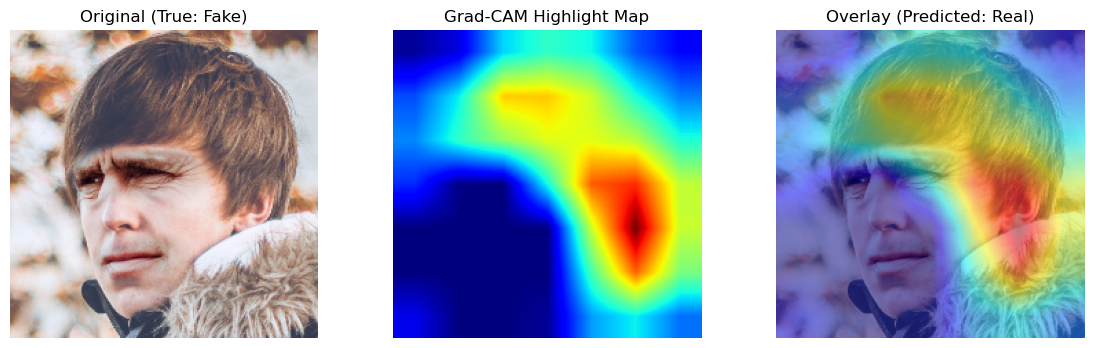


Evaluating a REAL image:


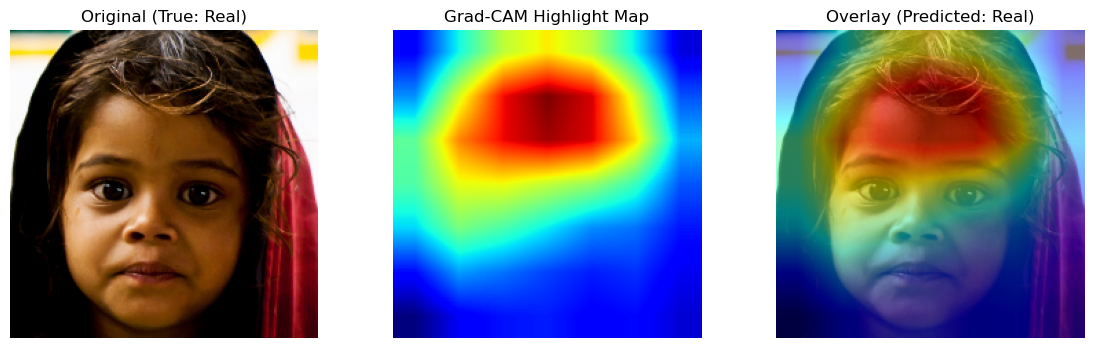


--- Heatmap Differences Explained ---
The heatmaps visually represent what activated the CNN the most (warm/red regions).
- For Fake Images: You will often see the heatmaps focusing on edge distortions, blurred backgrounds, asymmetry, or highly unnatural skin/hair textures where the generative AI struggled with consistency.
- For Real Images: The heatmaps generally spread more evenly across structural focal points like the eyes, structural facial symmetry, or consistent lighting vectors that denote physical presence.



In [8]:
# We attach the Grad-CAM hook to the final convolutional layer of ResNet-18
target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

def visualize_heatmap(img_path, true_label):
    # Load standard image with OpenCV for overlaying
    rgb_img = cv2.imread(img_path, 1)[:, :, ::-1] # BGR to RGB
    rgb_img = cv2.resize(rgb_img, (224, 224))
    rgb_img_float = np.float32(rgb_img) / 255
    
    # Pre-process specifically for the model inference
    input_tensor = test_transform(Image.fromarray(rgb_img)).unsqueeze(0).to(device)
    
    # We target index 0 because our Linear Output layer only has 1 node
    targets = [ClassifierOutputTarget(0)]
    
    # Compute activation map
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)
    
    model.eval()
    with torch.no_grad():
        pred_prob = torch.sigmoid(model(input_tensor)).item()
        pred_label = "Real" if pred_prob > 0.5 else "Fake"
    
    # Plotting
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    
    axes[0].imshow(rgb_img_float)
    axes[0].set_title(f"Original (True: {true_label})")
    axes[0].axis('off')
    
    axes[1].imshow(grayscale_cam, cmap='jet')
    axes[1].set_title("Grad-CAM Highlight Map")
    axes[1].axis('off')
    
    axes[2].imshow(visualization)
    axes[2].set_title(f"Overlay (Predicted: {pred_label})")
    axes[2].axis('off')
    
    plt.show()

# Pick one Fake and one Real image dynamically from the test set
sample_fake = test_df[test_df['label'] == 'Fake'].iloc[0]['filepath']
sample_real = test_df[test_df['label'] == 'Real'].iloc[0]['filepath']

print("Evaluating a FAKE image:")
visualize_heatmap(sample_fake, "Fake")

print("\nEvaluating a REAL image:")
visualize_heatmap(sample_real, "Real")

print("""
--- Heatmap Differences Explained ---
The heatmaps visually represent what activated the CNN the most (warm/red regions).
- For Fake Images: You will often see the heatmaps focusing on edge distortions, blurred backgrounds, asymmetry, or highly unnatural skin/hair textures where the generative AI struggled with consistency.
- For Real Images: The heatmaps generally spread more evenly across structural focal points like the eyes, structural facial symmetry, or consistent lighting vectors that denote physical presence.
""")